# Node Degree Analysis
This notebook loads the segment-wise correlation matrices and computes the binary node degree using a specified threshold.

In [1]:
import os
import pandas as pd
import numpy as np
from tqdm import tqdm

base_dir = '/home/aloo/CNS_Summer_Project_1/correlation_matrices_segment_wise_(notAbsolute)'

# 1. Identify subjects with multiple sessions
subjects_with_multiple_sessions = []
for subject in os.listdir(base_dir):
    if subject.startswith('sub-'):
        subject_path = os.path.join(base_dir, subject)
        if os.path.isdir(subject_path):
            sessions = [d for d in os.listdir(subject_path) if d.startswith('ses-')]
            if len(sessions) > 1:
                subjects_with_multiple_sessions.append(subject)

# 2. Exclude sub-NORB00074
excluded_subjects = ['sub-NORB00074']
filtered_subjects = sorted([sub for sub in subjects_with_multiple_sessions if sub not in excluded_subjects])
print(f"Found {len(filtered_subjects)} filtered subjects.")

# 3. Define chosen segments (1 to 8)
num_segments = 8
segment_keys = [f"segment-{str(i).zfill(2)}" for i in range(1, num_segments + 1)]

segment_matrices = {}

# Load only filtered subjects and specific segments for ses-1
for subject in tqdm(filtered_subjects, desc="Loading subjects"):
    subject_path = os.path.join(base_dir, subject)
    ses_path = os.path.join(subject_path, 'ses-1')
    
    if os.path.isdir(ses_path):
        segment_matrices[subject] = {}
        for file in os.listdir(ses_path):
            if file.endswith('.csv'):
                # Extract segment name
                parts = file.split('_')
                segment = next((p for p in parts if p.startswith('segment-')), None)
                
                # Only load if segment is in our chosen list
                if segment in segment_keys:
                    file_path = os.path.join(ses_path, file)
                    df = pd.read_csv(file_path, index_col=0)
                    segment_matrices[subject][segment] = df

print(f"Successfully loaded correlation matrices for {len(segment_matrices)} subjects and {num_segments} segments.")

Found 20 filtered subjects.


Loading subjects: 100%|██████████| 20/20 [00:00<00:00, 92.07it/s]

Successfully loaded correlation matrices for 20 subjects and 8 segments.


In [2]:
# Calculate Node Degree using Thresholding
threshold = 0.3  # You can adjust this threshold as needed
node_degrees_segment = {}
rows = []

for subject, segments in tqdm(segment_matrices.items(), desc="Computing node degrees"):
    node_degrees_segment[subject] = {}
    for segment, df in segments.items():
        # Use absolute correlation values
        abs_df = df.abs()
        
        # Create a binary adjacency matrix based on the threshold
        adj_matrix = (abs_df > threshold).astype(int)
        
        # Set diagonal to 0 to avoid counting self-connections
        np.fill_diagonal(adj_matrix.values, 0)
        
        # Sum the rows to get the degree of each node
        degrees = adj_matrix.sum(axis=1)
        node_degrees_segment[subject][segment] = degrees.to_dict()
        
        # Flatten into rows for a DataFrame
        for node, degree in degrees.items():
            rows.append({
                'subject': subject,
                'segment': segment,
                'node': node,
                'degree': degree
            })

node_degree_df = pd.DataFrame(rows)
print(f"Computed binary node degrees for all segments. DataFrame shape: {node_degree_df.shape}")

# Display the first few rows
node_degree_df.head()

Computing node degrees:   0%|          | 0/20 [00:00<?, ?it/s]

Computing node degrees: 100%|██████████| 20/20 [00:00<00:00, 240.06it/s]

Computed binary node degrees for all segments. DataFrame shape: (3040, 4)


,subject,segment,node,degree
0,sub-NORB00064,segment-01,Fp1,11
1,sub-NORB00064,segment-01,Fp2,9
2,sub-NORB00064,segment-01,F3,9
3,sub-NORB00064,segment-01,F4,9
4,sub-NORB00064,segment-01,C3,14


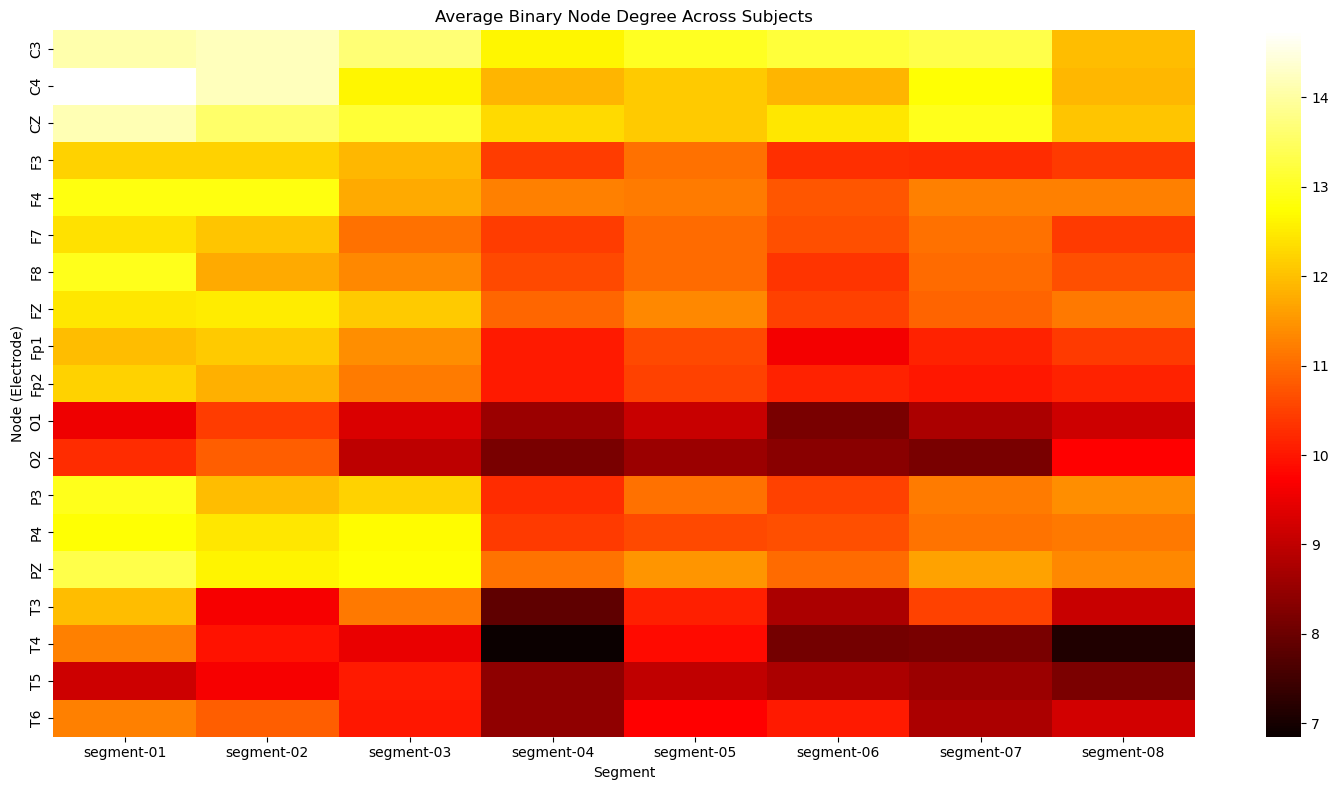

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

# Group by node and segment, calculating the mean degree across all subjects
heatmap_data = node_degree_df.groupby(['node', 'segment'])['degree'].mean().unstack()

# Sort columns to ensure segments are in order (if not already)
heatmap_data = heatmap_data.sort_index(axis=1)

# Plot the heatmap
plt.figure(figsize=(15, 8))
sns.heatmap(heatmap_data, cmap='hot', annot=False)
plt.title('Average Binary Node Degree Across Subjects')
plt.xlabel('Segment')
plt.ylabel('Node (Electrode)')
plt.tight_layout()
plt.show()